# Variable selection and model selection

The main feature of multiple linear regression is that it uses several explanatory variables together. Therefore, the natural question is: which variables should I use to build the best possible model for my objective? This question leads us to introduce model evaluation criteria and variable selection methods.

## What will you learn in this course? 🧐🧐

This course focuses on evaluation methods for multiple linear regression models.

* Evaluation of multiple linear regression models
    * Analysis of Variance (ANOVA)
    * Fisher's F-statistic
    * $R^{2}$ (R squared)
    * $R^2_{adjusted}$
    * P-values
* Model selection
    * Step-by-step methods
* Final remarks



## Evaluation of multiple linear regression models 💯

Some of the evaluation criteria presented below can also be used for models other than multiple linear regression. This is why it is important to introduce them now and to remember how to interpret each of them.


### Analysis of Variance (ANOVA)

The analysis of variance quantifies the performance of a statistical model in terms of estimation error. The values we discuss now will be used to build other performance metrics:

* SST: the Sum of Squares Total measures the dispersion of the values of the target variable $Y$ (denoted $y_{1}, ..., y_{n}$) over the population considered. Mathematically:

$$
SST = \sum_{i=1}^{n}(y_{i}-\bar{y})^2
$$

It is the sum of the squared deviations from the mean of the target variable $Y$ for the $n$ observations considered.

* SSE: the Sum of Squares Explained represents the amount of dispersion of the target variable that is explained by the model. It is defined as:

$$
SSE = \sum_{i=1}^{n}(\hat{y}_{i}-\bar{y})^2
$$

It is the sum of the squared differences between the model's estimate for each observation and the mean of the target variable over the population of interest. In statistics, variation is information: you cannot possibly differentiate samples if they are all described by the exact same set of values.

* SSR: the Sum of Squared Residuals quantifies the error made by the model, in other words the part of the dispersion of the target variable that is not explained by the model (hence the name "residual"). Its formula is:

$$
SSR =\sum_{i=1}^{n}(y_{i}-\hat{y}_{i})^2
$$

It is essential to understand these values, because we will use them to build all the evaluation metrics for multiple linear regression that we will see now.

To summarize, SST (in red in the figure below) is proportional to the total variance of the target variable, which can be decomposed into two components:
* SSE is the variance explained by the model, proportional to the variance of our estimates around the actual mean of the observed population;
* SSR (in blue in the figure below) is the sum of the squared differences between our estimates and the actual values of the target variable.

In other words, SST is the total amount of information, SSE is the information explained by the model, and SSR is the information that remains to be explained, i.e. the error made.


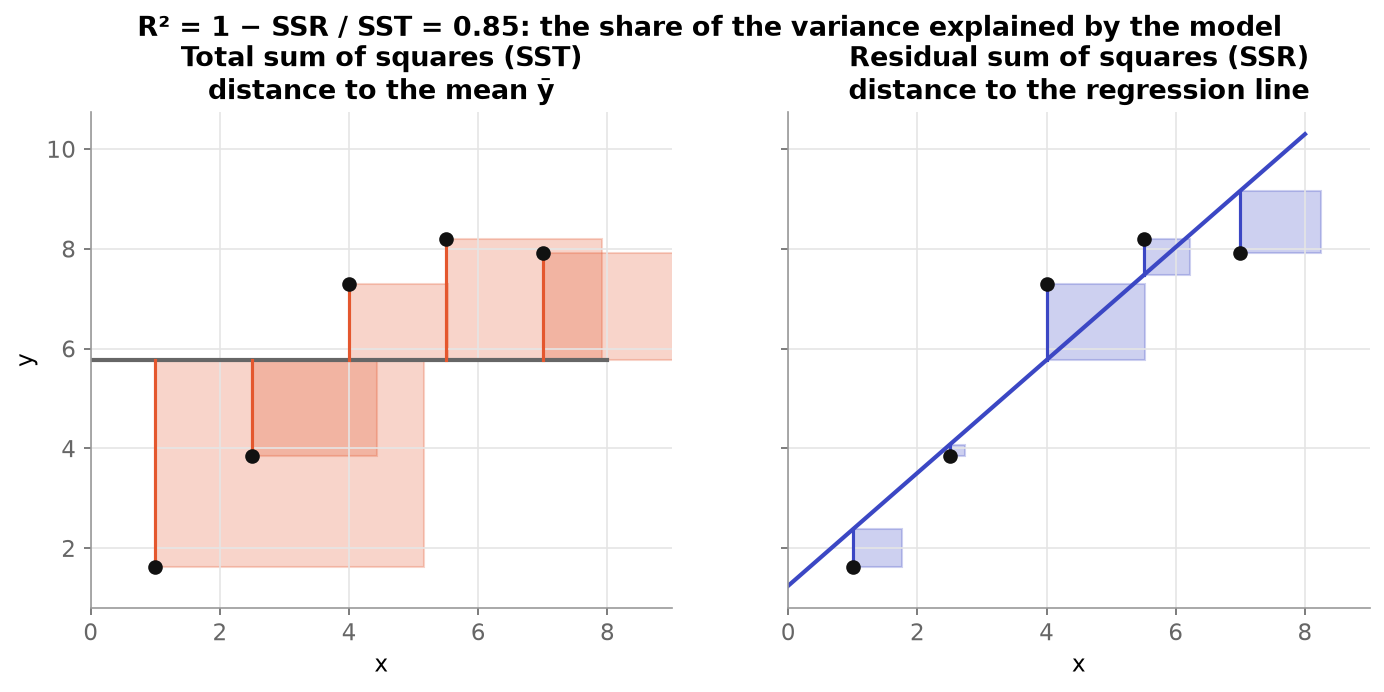


* $R^{2}$ (R squared)

$R^{2}$, or R-squared, is a statistic that quantifies the explanatory power of the model with respect to the target variable.

$$
R^{2} = 1-\frac{SSR}{SST}
$$

$R^2$ varies between 0 and 1. If the model is not very relevant, the sum of squared residuals $SSR$ is close to the total sum of squares $SST$, and $R^{2}$ is close to 0. On the contrary, if the model explains the target variable faithfully, then $SSR$ is close to 0 and $R^2$ is close to 1.

$R^2$ never decreases when you add an explanatory variable: mechanically, each new variable makes the prediction of the target variable $Y$ on the training data at least as good, so $R^2$ gets higher (or stays the same). This is why $R^2$ should only be used to compare models that have the same number of explanatory variables.

## Model selection 🤔🤔

When we have $p$ explanatory variables, we can count the number of possible models in the following way: each explanatory variable can be either in the model or not, so we can potentially build $2^p$ models. In practice, when the number $p$ of explanatory variables is large, we cannot reasonably explore all the $2^p$ models to select the best one. Several methods exist to avoid this brute-force approach.

### Step by step

Step-by-step selection comes in three variants:

* Forward selection: the variables are added to the model one by one. At each step, we add the variable that maximizes the score on the test set ($R^2$ in the case of linear regression). The procedure stops when all the variables are used, or when the score on the test set starts decreasing.
* Backward elimination: this time, we start with a model using all the explanatory variables. At each step, we remove the variable with the highest p-value (the p-value of Student's t-test on its coefficient). The procedure stops when all the remaining variables have p-values lower than a threshold, set by default at 0.05 (it can be adapted to the precision needs of the problem). This technique is difficult to implement with scikit-learn, since the p-values have to be calculated by hand.
* Stepwise: this algorithm alternates between selection and elimination. After each addition of a variable, an elimination step removes the variables that have become less relevant in the presence of the new one. For example, if after adding the most useful variable (according to the test score) one of the variables becomes non-significant, we remove it and proceed with a new forward selection step.

### Final Notes

The model evaluation and selection methods introduced above are valid for all linear models, as well as for logistic regression, which we will discuss later.

## Resources 📚📚

* How do I interpret R Squared - https://blog.minitab.com/en/blog/adventures-in-statistics-2/regression-analysis-how-do-i-interpret-r-squared-and-assess-the-goodness-of-fit
* Adjusted R Squared - https://blog.minitab.com/en/blog/adventures-in-statistics-2/multiple-regession-analysis-use-adjusted-r-squared-and-predicted-r-squared-to-include-the-correct-number-of-variables